<!-- SPDX-FileCopyrightText: Copyright (c) 2026 NVIDIA CORPORATION & AFFILIATES. All rights reserved.
SPDX-License-Identifier: OpenMDW-1.1 -->

# Cosmos3 Generator Audiovisual with Diffusers

This notebook runs Cosmos3 audiovisual generation directly with `Cosmos3OmniPipeline`.

Run the Cosmos3-Nano, Cosmos3-Super, or Cosmos3-Edge examples independently. Cosmos3-Edge has no audio modules and uses its 480p generation settings. The notebook also includes Nano and Super video-to-video examples, while Super T2V/I2V examples run without audio. Each section loads the matching model explicitly.

Note: if you have already completed steps 1-3 and installed the `Cosmos3 Diffusers (Python 3.13)` kernel, switch to that kernel and jump directly to step 4. Run the restore cell there, then continue with verification and the examples.


## 1. Prerequisites

Use a Linux machine with NVIDIA GPU access, model access on Hugging Face, and either `uvx hf@latest auth login` or `HF_TOKEN` set.

Generator requires the Guardrail. Request access to the gated [nvidia/Cosmos-1.0-Guardrail](https://huggingface.co/nvidia/Cosmos-1.0-Guardrail) HF repository before running these examples. To disable the guardrail, set `enable_safety_checker=False` (Diffusers), `guardrails: false` (vLLM-Omni `extra_params`/`extra_args`), or `--no-guardrails` (Cosmos Framework).

> **Headless servers:** if you see an error like `libxcb.so.1: cannot open shared object file` (a missing system graphics library) when importing or running the pipeline, install the required system libraries:
>
> ```bash
> apt-get install -y libxcb1 libgl1 libglib2.0-0
> ```

> **uv version:** these notebooks need `uv >= 0.11.3`. Older versions fail to parse the project config and do not recognize newer `--torch-backend` values such as `cu130` (you may see errors like `a value is required for '--torch-backend'` or an invalid-value list that stops at `cu129`). If you hit version-related errors, upgrade with `uv self update` (or reinstall from https://astral.sh/uv).


## 2. Configure Paths and Environment

The defaults are relative to this `cosmos` checkout and use the CUDA 13 or 12.8 Torch backend depending on the CUDA version installed on your system (`cu130` or `cu128`):

```bash
export COSMOS3_DIFFUSERS_VENV=/path/to/.venv-cosmos3-diffusers
export COSMOS3_TORCH_BACKEND=cu130
export HF_HOME=/path/to/large/huggingface/cache
export UV_LINK_MODE=copy
export CUDA_VISIBLE_DEVICES=0
```


In [1]:
from pathlib import Path
import os


def find_repo_root(start: Path) -> Path:
    for path in [start, *start.parents]:
        if (path / "README.md").exists() and (path / "cookbooks").exists():
            return path
    return start


def configure_diffusers_environment() -> None:
    global COSMOS_ROOT
    global COSMOS3_AUDIOVISUAL_ROOT
    global COSMOS3_DIFFUSERS_VENV
    global COSMOS3_TORCH_BACKEND
    global COSMOS3_AUDIOVISUAL_OUTPUT_ROOT

    COSMOS_ROOT = find_repo_root(Path.cwd().resolve())
    COSMOS3_AUDIOVISUAL_ROOT = COSMOS_ROOT / "cookbooks" / "cosmos3" / "generator" / "audiovisual"
    COSMOS3_DIFFUSERS_VENV = Path(
        os.environ.get("COSMOS3_DIFFUSERS_VENV", COSMOS_ROOT / ".venv-cosmos3-diffusers")
    ).resolve()
    COSMOS3_TORCH_BACKEND = os.environ.get("COSMOS3_TORCH_BACKEND", "cu130")
    COSMOS3_AUDIOVISUAL_OUTPUT_ROOT = Path(
        os.environ.get("COSMOS3_AUDIOVISUAL_OUTPUT_ROOT", COSMOS3_AUDIOVISUAL_ROOT / "outputs" / "notebooks")
    ).resolve()

    os.environ["COSMOS3_DIFFUSERS_VENV"] = str(COSMOS3_DIFFUSERS_VENV)
    os.environ["COSMOS3_TORCH_BACKEND"] = COSMOS3_TORCH_BACKEND
    os.environ["COSMOS3_AUDIOVISUAL_OUTPUT_ROOT"] = str(COSMOS3_AUDIOVISUAL_OUTPUT_ROOT)
    os.environ.setdefault("UV_CACHE_DIR", str(Path.home() / ".cache" / "uv"))
    os.environ.setdefault("UV_LINK_MODE", "copy")
    os.environ.setdefault("HF_HOME", str(Path.home() / ".cache" / "huggingface"))
    os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")

    print(f"COSMOS_ROOT: {COSMOS_ROOT}")
    for key in [
        "COSMOS3_DIFFUSERS_VENV",
        "COSMOS3_TORCH_BACKEND",
        "COSMOS3_AUDIOVISUAL_OUTPUT_ROOT",
        "UV_CACHE_DIR",
        "UV_LINK_MODE",
        "HF_HOME",
        "HF_HUB_DISABLE_XET",
        "CUDA_VISIBLE_DEVICES",
    ]:
        print(f"{key}: {os.environ[key]}")
    print("HF_TOKEN:", "<set>" if os.environ.get("HF_TOKEN") else "<unset>")


configure_diffusers_environment()


COSMOS_ROOT: /home/arrl/jaeyu/cosmos3/git/cosmos
COSMOS3_DIFFUSERS_VENV: /home/arrl/jaeyu/cosmos3/git/cosmos/.venv-cosmos3-diffusers
COSMOS3_TORCH_BACKEND: cu130
COSMOS3_AUDIOVISUAL_OUTPUT_ROOT: /home/arrl/jaeyu/cosmos3/git/cosmos/cookbooks/cosmos3/generator/audiovisual/outputs/notebooks
UV_CACHE_DIR: /home/arrl/.cache/uv
UV_LINK_MODE: copy
HF_HOME: /home/arrl/.cache/huggingface
HF_HUB_DISABLE_XET: 1
CUDA_VISIBLE_DEVICES: 0
HF_TOKEN: <unset>


## 3. Install Diffusers Dependencies


In [2]:
%%bash
set -euo pipefail

if ! command -v uv >/dev/null 2>&1; then
  echo "uv is not installed. Install it first: https://docs.astral.sh/uv/getting-started/installation/"
  exit 1
fi

export UV_LINK_MODE="${UV_LINK_MODE:-copy}"
uv venv "$COSMOS3_DIFFUSERS_VENV" --python 3.13 --seed --managed-python --allow-existing
source "$COSMOS3_DIFFUSERS_VENV/bin/activate"
uv pip install --torch-backend="$COSMOS3_TORCH_BACKEND" \
  "diffusers @ git+https://github.com/huggingface/diffusers.git" \
  accelerate \
  av \
  cosmos_guardrail \
  huggingface_hub \
  imageio \
  imageio-ffmpeg \
  ipykernel \
  torch \
  torchvision \
  transformers

"$COSMOS3_DIFFUSERS_VENV/bin/python" -m ipykernel install --user \
  --name cosmos3-diffusers \
  --display-name "Cosmos3 Diffusers (Python 3.13)"

echo
echo "Installed dependencies into: $COSMOS3_DIFFUSERS_VENV"
echo "Next: switch this notebook kernel to: Cosmos3 Diffusers (Python 3.13)"
echo "After switching kernels, run the Restore Environment cell below, then continue with Verify."


Using CPython 3.13.15
Creating virtual environment with seed packages at: /home/arrl/jaeyu/cosmos3/git/cosmos/.venv-cosmos3-diffusers


Activate with: source /home/arrl/jaeyu/cosmos3/git/cosmos/.venv-cosmos3-diffusers/bin/activate
Using Python 3.13.15 environment at: /home/arrl/jaeyu/cosmos3/git/cosmos/.venv-cosmos3-diffusers
Resolved 107 packages in 922ms
Checked 107 packages in 0.28ms


Installed kernelspec cosmos3-diffusers in /home/arrl/.local/share/jupyter/kernels/cosmos3-diffusers

Installed dependencies into: /home/arrl/jaeyu/cosmos3/git/cosmos/.venv-cosmos3-diffusers
Next: switch this notebook kernel to: Cosmos3 Diffusers (Python 3.13)
After switching kernels, run the Restore Environment cell below, then continue with Verify.


## 4. Select the Diffusers Kernel

The install cell creates and registers the `Cosmos3 Diffusers (Python 3.13)` Jupyter kernel. 

**Note**: Switch this notebook to that kernel before running the remaining Python cells, then run the restore cell immediately below. It can take some time for the new Jupyter kernel to show up in the notebook interface.

In [3]:
# Run this cell immediately after switching to the Cosmos3 Diffusers kernel.
# It restores the same paths and cache settings as the setup cell above.
from pathlib import Path
import os


def find_repo_root(start: Path) -> Path:
    for path in [start, *start.parents]:
        if (path / "README.md").exists() and (path / "cookbooks").exists():
            return path
    return start


def configure_diffusers_environment() -> None:
    global COSMOS_ROOT
    global COSMOS3_AUDIOVISUAL_ROOT
    global COSMOS3_DIFFUSERS_VENV
    global COSMOS3_TORCH_BACKEND
    global COSMOS3_AUDIOVISUAL_OUTPUT_ROOT

    COSMOS_ROOT = find_repo_root(Path.cwd().resolve())
    COSMOS3_AUDIOVISUAL_ROOT = COSMOS_ROOT / "cookbooks" / "cosmos3" / "generator" / "audiovisual"
    COSMOS3_DIFFUSERS_VENV = Path(
        os.environ.get("COSMOS3_DIFFUSERS_VENV", COSMOS_ROOT / ".venv-cosmos3-diffusers")
    ).resolve()
    COSMOS3_TORCH_BACKEND = os.environ.get("COSMOS3_TORCH_BACKEND", "cu130")
    COSMOS3_AUDIOVISUAL_OUTPUT_ROOT = Path(
        os.environ.get("COSMOS3_AUDIOVISUAL_OUTPUT_ROOT", COSMOS3_AUDIOVISUAL_ROOT / "outputs" / "notebooks")
    ).resolve()

    os.environ["COSMOS3_DIFFUSERS_VENV"] = str(COSMOS3_DIFFUSERS_VENV)
    os.environ["COSMOS3_TORCH_BACKEND"] = COSMOS3_TORCH_BACKEND
    os.environ["COSMOS3_AUDIOVISUAL_OUTPUT_ROOT"] = str(COSMOS3_AUDIOVISUAL_OUTPUT_ROOT)
    os.environ.setdefault("UV_CACHE_DIR", str(Path.home() / ".cache" / "uv"))
    os.environ.setdefault("UV_LINK_MODE", "copy")
    os.environ.setdefault("HF_HOME", str(Path.home() / ".cache" / "huggingface"))
    os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")

    print(f"COSMOS_ROOT: {COSMOS_ROOT}")
    for key in [
        "COSMOS3_DIFFUSERS_VENV",
        "COSMOS3_TORCH_BACKEND",
        "COSMOS3_AUDIOVISUAL_OUTPUT_ROOT",
        "UV_CACHE_DIR",
        "UV_LINK_MODE",
        "HF_HOME",
        "HF_HUB_DISABLE_XET",
        "CUDA_VISIBLE_DEVICES",
    ]:
        print(f"{key}: {os.environ[key]}")
    print("HF_TOKEN:", "<set>" if os.environ.get("HF_TOKEN") else "<unset>")


configure_diffusers_environment()


COSMOS_ROOT: /home/arrl/jaeyu/cosmos3/git/cosmos
COSMOS3_DIFFUSERS_VENV: /home/arrl/jaeyu/cosmos3/git/cosmos/.venv-cosmos3-diffusers
COSMOS3_TORCH_BACKEND: cu130
COSMOS3_AUDIOVISUAL_OUTPUT_ROOT: /home/arrl/jaeyu/cosmos3/git/cosmos/cookbooks/cosmos3/generator/audiovisual/outputs/notebooks
UV_CACHE_DIR: /home/arrl/.cache/uv
UV_LINK_MODE: copy
HF_HOME: /home/arrl/.cache/huggingface
HF_HUB_DISABLE_XET: 1
CUDA_VISIBLE_DEVICES: 0
HF_TOKEN: <unset>


## 5. Verify GPU and Python Environment


In [4]:
import os
import sys
from pathlib import Path

if "COSMOS3_DIFFUSERS_VENV" not in os.environ:
    raise RuntimeError("Run the Restore Environment cell after switching to the Diffusers kernel.")

expected_python = (Path(os.environ["COSMOS3_DIFFUSERS_VENV"]) / "bin" / "python").resolve()
current_python = Path(sys.executable).resolve()
print("kernel python:", current_python)
print("expected python:", expected_python)
if current_python != expected_python:
    raise RuntimeError(
        "This notebook is not running inside the Diffusers venv. "
        "Switch the notebook kernel to 'Cosmos3 Diffusers (Python 3.13)', then run the Restore Environment cell above."
    )

import torch
import diffusers

print("diffusers:", diffusers.__version__)
print("torch:", torch.__version__)
print("torch cuda:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())
print("device count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("device 0:", torch.cuda.get_device_name(0))


kernel python: /home/arrl/.local/share/uv/python/cpython-3.13.15-linux-x86_64-gnu/bin/python3.13
expected python: /home/arrl/.local/share/uv/python/cpython-3.13.15-linux-x86_64-gnu/bin/python3.13


/home/arrl/jaeyu/cosmos3/git/cosmos/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


diffusers: 0.41.0.dev0
torch: 2.13.0+cu129
torch cuda: 12.9
cuda available: True
device count: 1
device 0: NVIDIA GeForce RTX 3090


## 6. Preview Available Inputs


prompts/image2video:
  car_driving.json: The video begins with a dashcam view of a car driving fast along a scenic coastal mountain road, the asphalt rushing beneath and a sharp left curve sign visible on the left. The ca...
  car_driving_edge.json: The video begins with a dashcam view of a car driving fast along a scenic coastal mountain road, the asphalt rushing beneath and a sharp left curve sign visible on the left. The ca...
  coastal_road_audio.json: The video begins with a dashcam view of a car driving fast along a scenic coastal mountain road, the asphalt rushing beneath and a sharp left curve sign visible on the left. The ca...
  humanoid_robot.json: The video opens with a humanoid robot standing motionless in a modern living room. At around one second, the robot begins to shift its weight and bend its knees slightly. By two se...
  아틀라스_사진.json: The video begins with a featureless white humanoid robot standing upright in a dark studio-like environment. From 0:00 to 0:02, the 

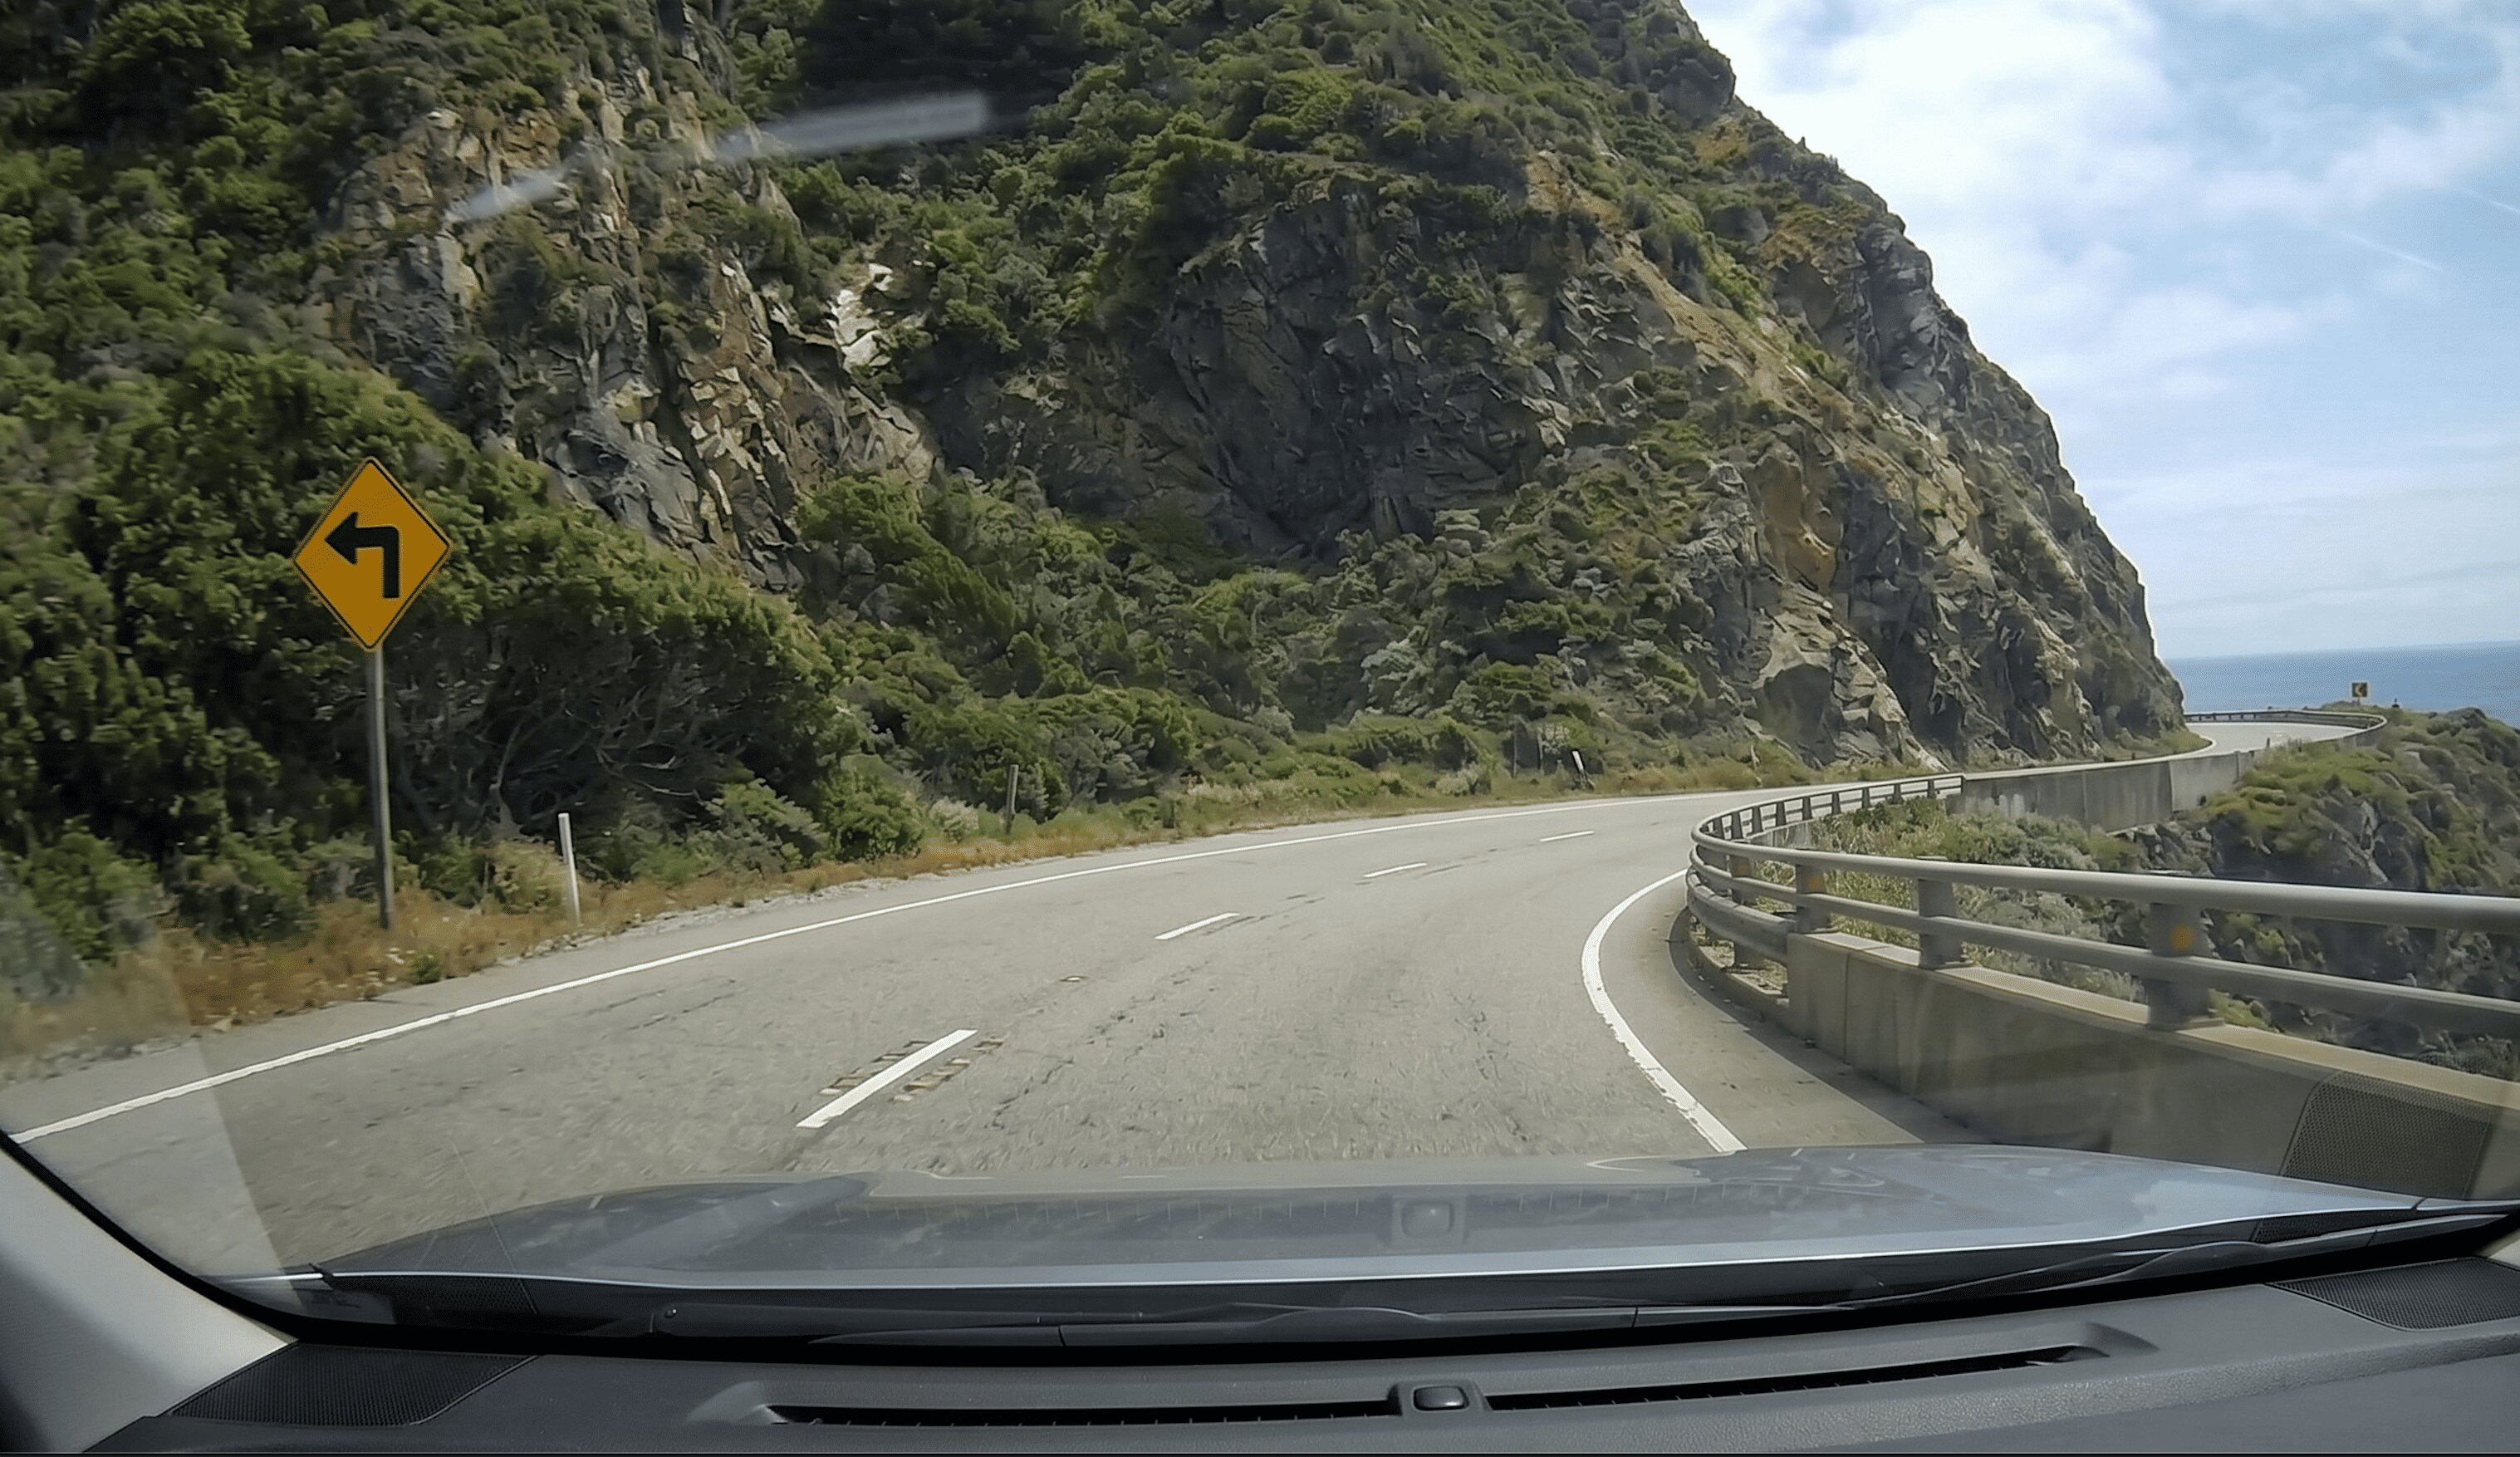

  coastal_road_audio.jpg


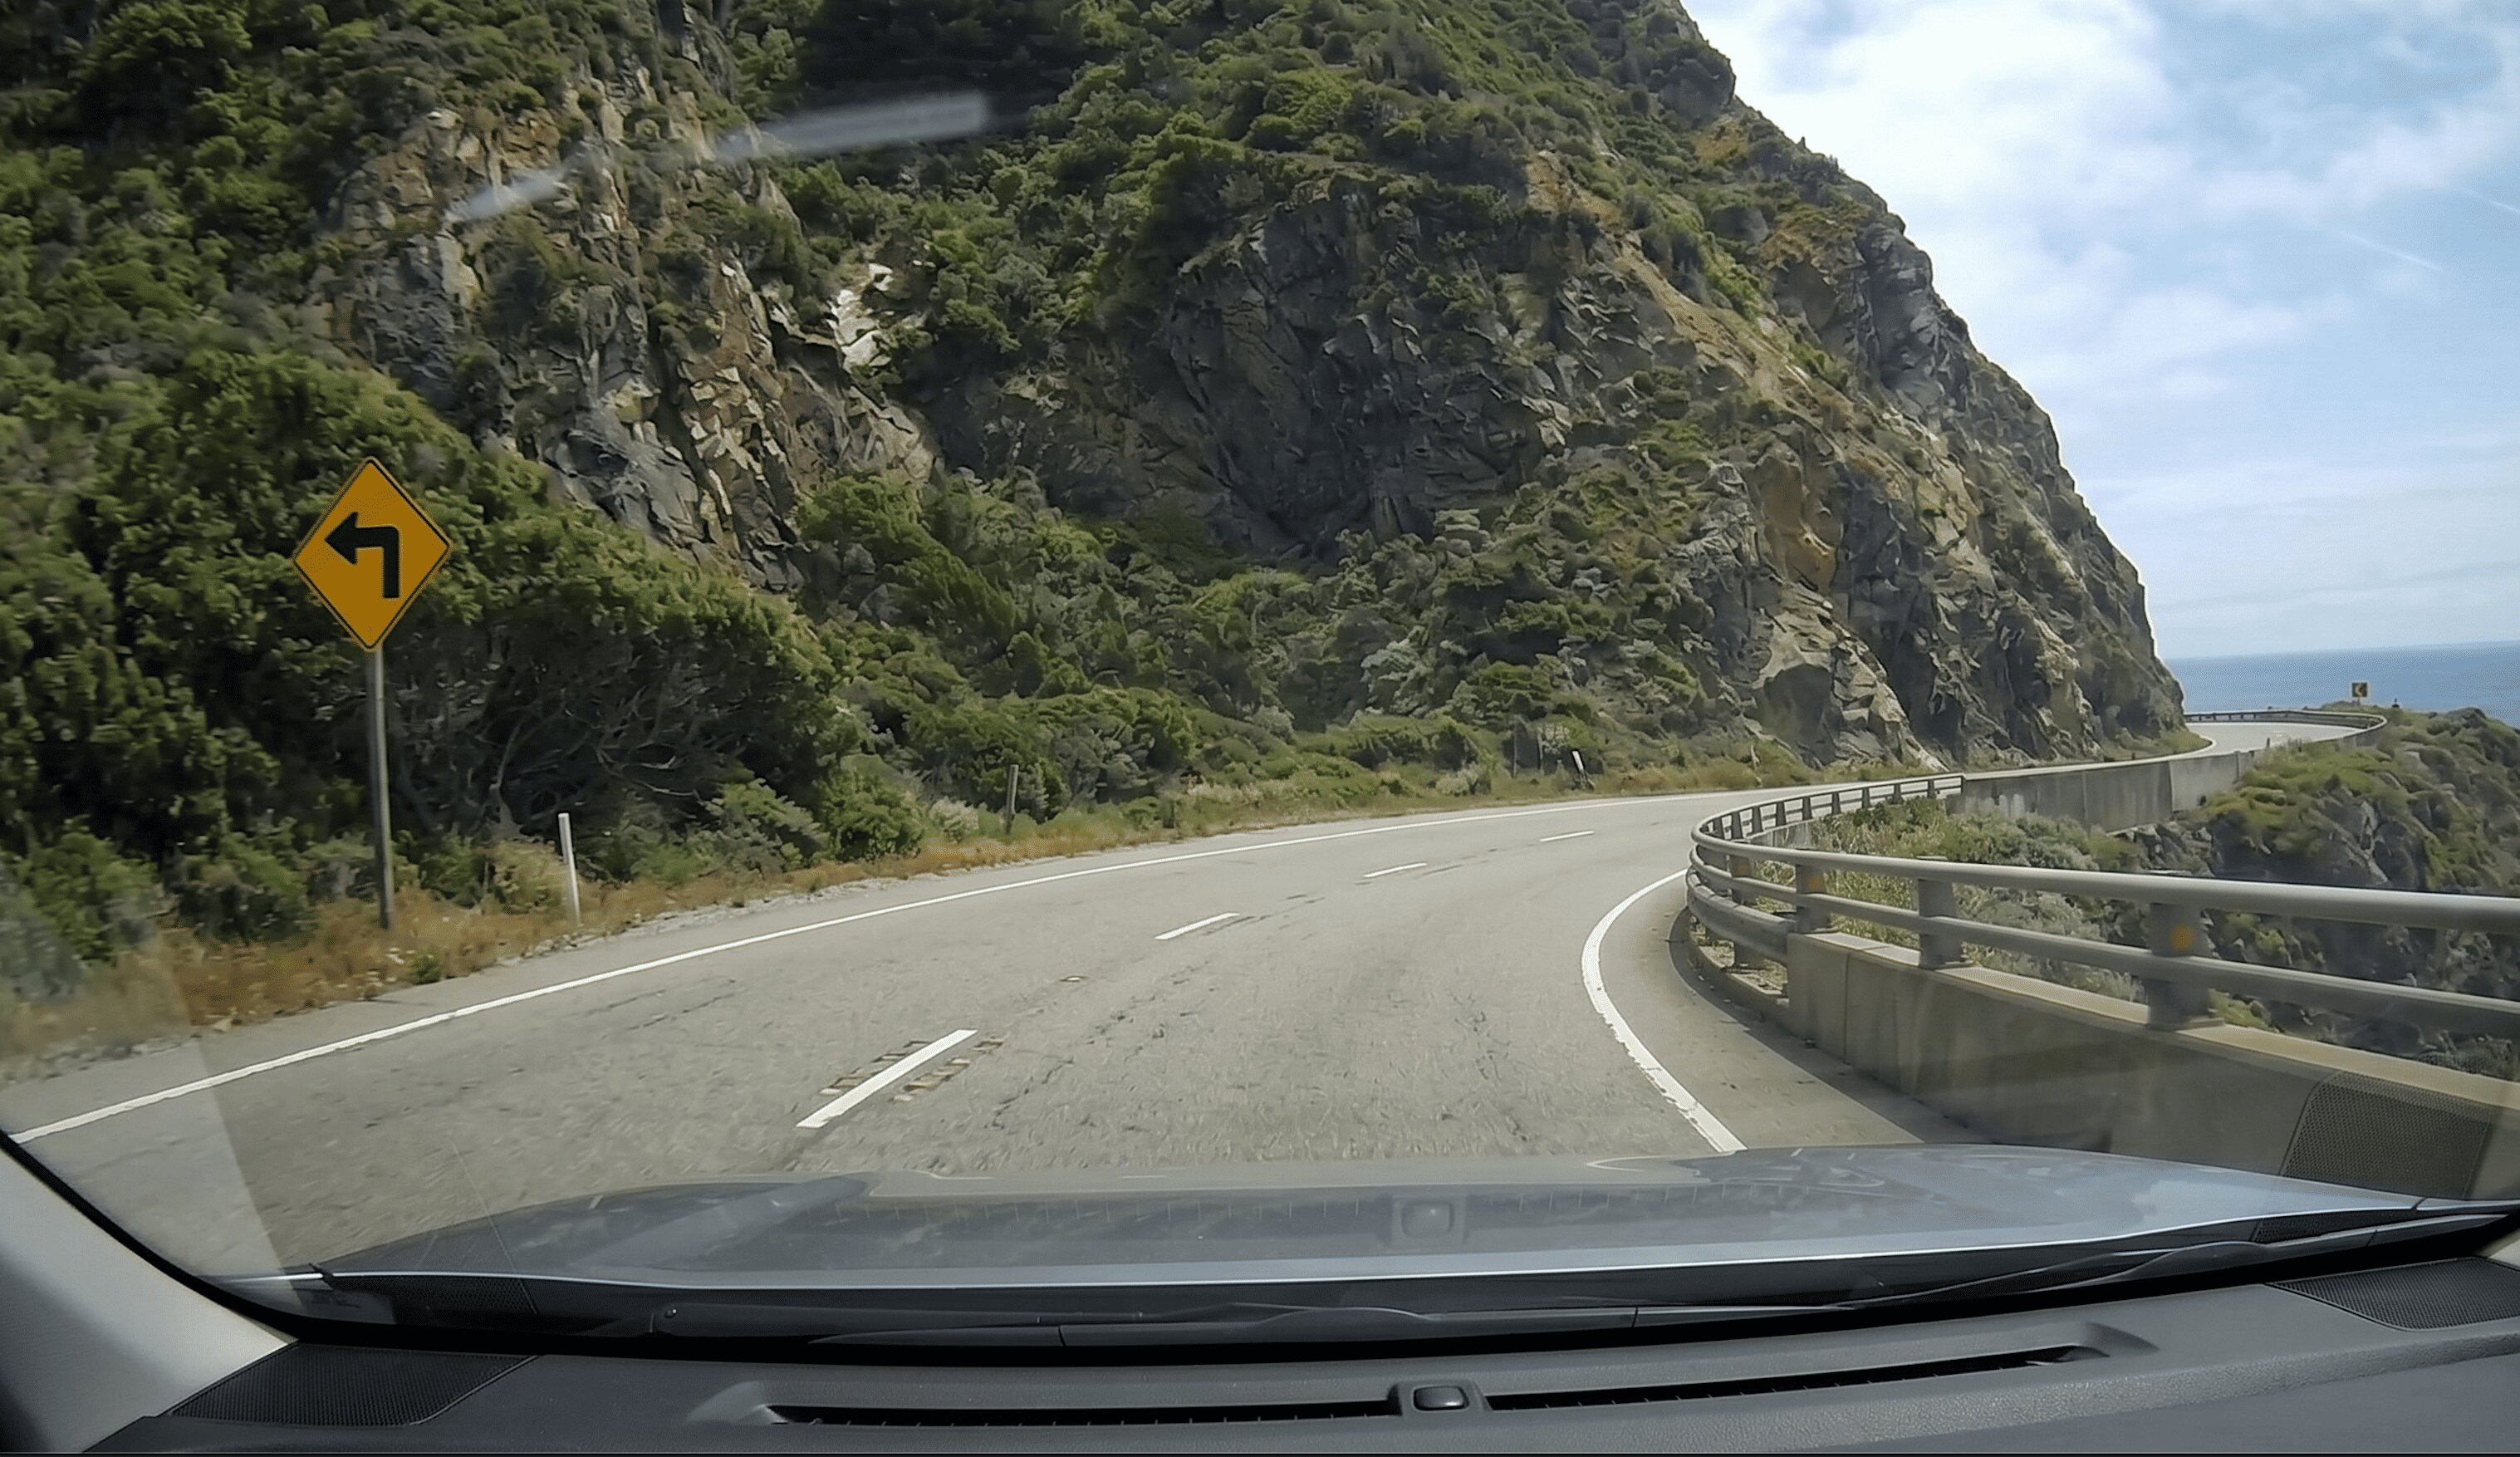

  humanoid_robot.jpg


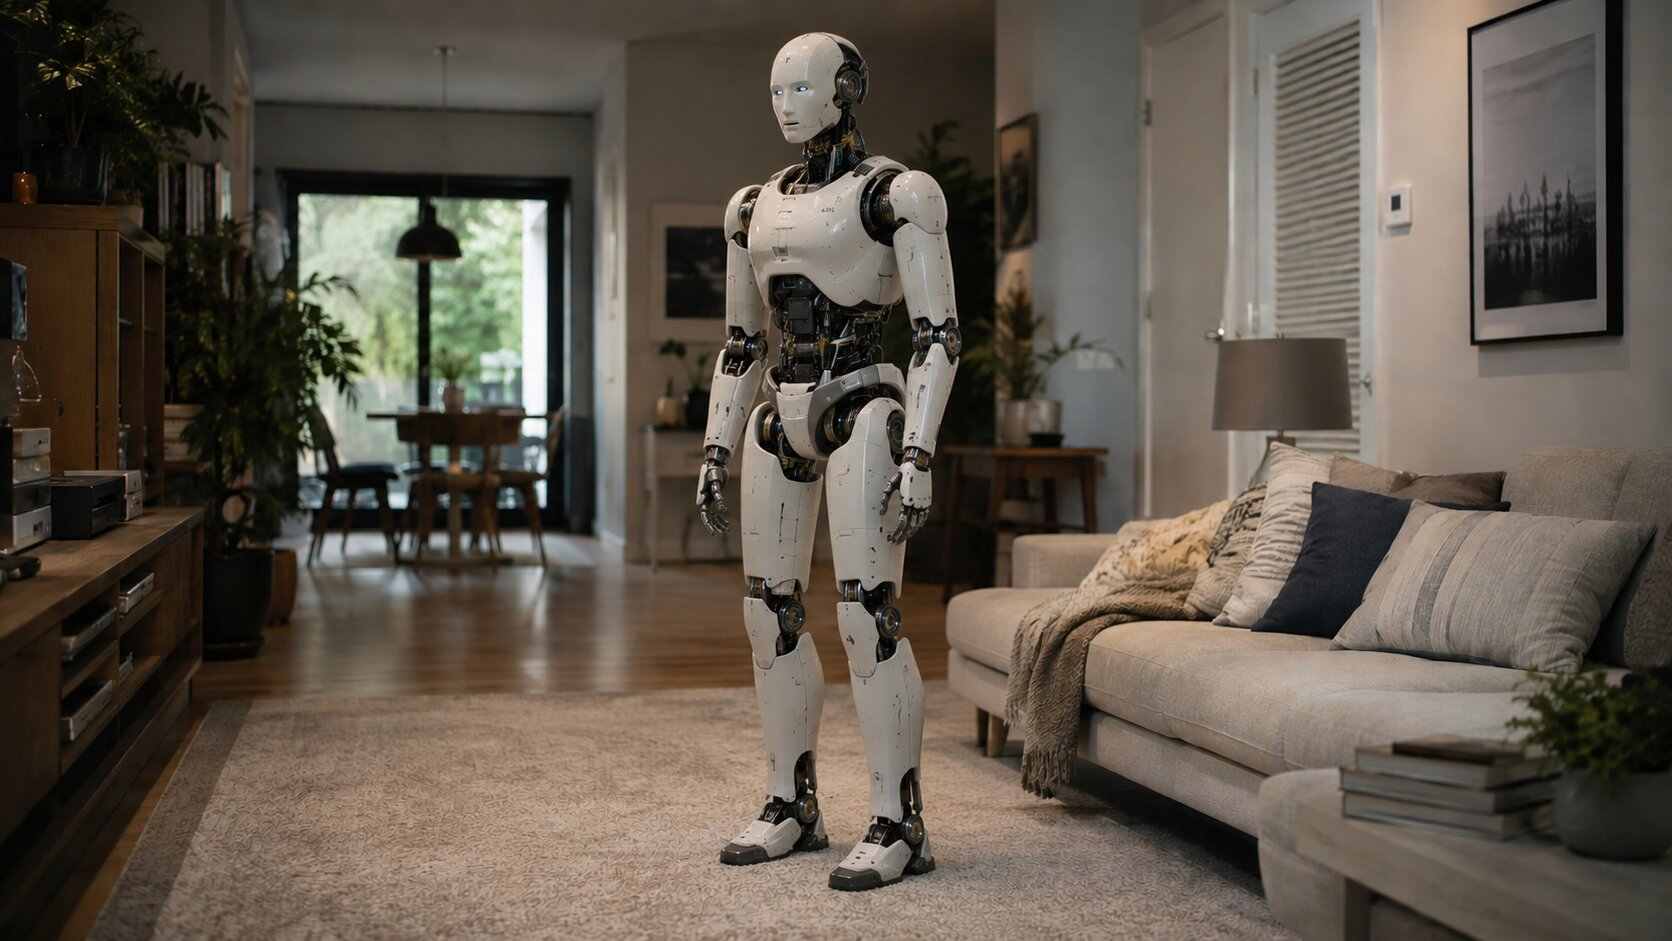

  아틀라스_사진.jpg


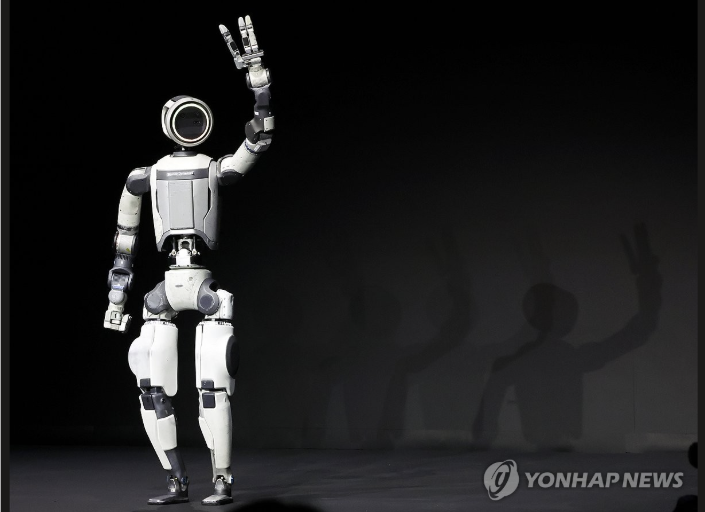

In [5]:
from pathlib import Path
import json
from IPython.display import Image, display

assets_dir = COSMOS3_AUDIOVISUAL_ROOT / "assets"
for prompt_dir in sorted((assets_dir / "prompts").iterdir()):
    if not prompt_dir.is_dir():
        continue
    print(f"{prompt_dir.relative_to(assets_dir)}:")
    for prompt_path in sorted(prompt_dir.glob("*.json")):
        data = json.loads(prompt_path.read_text())
        caption = (
            data.get("temporal_caption")
            or data.get("comprehensive_t2i_caption")
            or data.get("extra", {}).get("prompt", "")
        )
        print(f"  {prompt_path.name}: {caption[:180]}{'...' if len(caption) > 180 else ''}")
    print()

for image_dir in sorted((assets_dir / "images").iterdir()):
    if not image_dir.is_dir():
        continue
    print(f"{image_dir.relative_to(assets_dir)}:")
    for image_path in sorted(image_dir.iterdir()):
        if image_path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}:
            print(f"  {image_path.name}")
            display(Image(filename=str(image_path), width=420))


## 7. Define Asset Sets, Payload Helpers, Runner, and Viewer Helpers


In [6]:
import json
import os
from pathlib import Path
from IPython.display import Image, display

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

FIXED_SAMPLING = {
    "num_steps": 35,
    "guidance": 6.0,
    "shift": 10.0,
    "fps": 24,
    "num_frames": 189,
    "resolution": "720",
    "aspect_ratio": "16,9",
    "seed": 1234,
}

# All asset paths are repo-relative under cookbooks/cosmos3/generator/audiovisual.
# The Nano/Super cases without audio are intentionally separate so each run uses the matching model.
ASSET_SETS = {
    "t2i": {
        "model": "Cosmos3-Nano",
        "mode": "text2image",
        "prompt": "assets/prompts/text2image/robot_draping.json",
        "enable_sound": False,
    },
    "t2i_super": {
        "model": "Cosmos3-Super",
        "mode": "text2image",
        "prompt": "assets/prompts/text2image/robot_draping.json",
        "enable_sound": False,
    },
    "t2v_nano_noaudio": {
        "model": "Cosmos3-Nano",
        "mode": "text2video",
        "prompt": "assets/prompts/text2video/robot_kitchen.json",
        "enable_sound": False,
    },
    "t2vs": {
        "model": "Cosmos3-Nano",
        "mode": "text2video",
        "prompt": "assets/prompts/text2video/robot_pouring_water_audio.json",
        "enable_sound": True,
    },
    "i2v_nano_noaudio": {
        "model": "Cosmos3-Nano",
        "mode": "image2video",
        "prompt": "assets/prompts/image2video/car_driving.json",
        "image": "assets/images/image2video/car_driving.jpg",
        "enable_sound": False,
    },
    "i2v_edge_noaudio": {
        "model": "Cosmos3-Edge",
        "mode": "image2video",
        "prompt": "assets/prompts/image2video/아틀라스_사진.json",
        "image": "assets/images/image2video/아틀라스_사진.jpg",
        "enable_sound": False,
        "sampling": {
            "num_steps": 20,
            "guidance": 5.0,
            "shift": 8.0,
            "fps": 24,
            "num_frames": 121,
            "resolution": "480",
            "aspect_ratio": "16,9",
            "seed": 0,
        },
    },
    "i2vs": {
        "model": "Cosmos3-Nano",
        "mode": "image2video",
        "prompt": "assets/prompts/image2video/coastal_road_audio.json",
        "image": "assets/images/image2video/coastal_road_audio.jpg",
        "enable_sound": True,
    },
    "v2v_nano_noaudio": {
        "model": "Cosmos3-Nano",
        "mode": "video2video",
        "prompt": "assets/prompts/image2video/car_driving.json",
        "negative_prompt": "assets/negative_prompts/image2video/neg_prompt.json",
        "video": "assets/videos/car_driving_plain.mp4",
        "enable_sound": False,
    },
    "v2vs": {
        "model": "Cosmos3-Nano",
        "mode": "video2video",
        "prompt": "assets/prompts/image2video/car_driving.json",
        "negative_prompt": "assets/negative_prompts/image2video/neg_prompt.json",
        "video": "assets/videos/car_driving_plain.mp4",
        "enable_sound": True,
    },
    "t2v_super_noaudio": {
        "model": "Cosmos3-Super",
        "mode": "text2video",
        "prompt": "assets/prompts/text2video/robot_kitchen.json",
        "enable_sound": False,
    },
    "i2v_super_noaudio": {
        "model": "Cosmos3-Super",
        "mode": "image2video",
        "prompt": "assets/prompts/image2video/car_driving.json",
        "image": "assets/images/image2video/car_driving.jpg",
        "enable_sound": False,
    },
    "v2v_super_noaudio": {
        "model": "Cosmos3-Super",
        "mode": "video2video",
        "prompt": "assets/prompts/image2video/car_driving.json",
        "negative_prompt": "assets/negative_prompts/image2video/neg_prompt.json",
        "video": "assets/videos/car_driving_plain.mp4",
        "enable_sound": False,
    },
    "v2vs_super": {
        "model": "Cosmos3-Super",
        "mode": "video2video",
        "prompt": "assets/prompts/image2video/car_driving.json",
        "negative_prompt": "assets/negative_prompts/image2video/neg_prompt.json",
        "video": "assets/videos/car_driving_plain.mp4",
        "enable_sound": True,
    },
    # Distilled 4-step checkpoints bake classifier-free guidance into the weights and read their
    # sigma schedule from the checkpoint, so they carry no num_steps/guidance/shift.
    "t2i_distilled": {
        "model": "Cosmos3-Super-Text2Image-4Step",
        "mode": "text2image",
        "prompt": "assets/prompts/text2image/robot_draping.json",
        "enable_sound": False,
        "distilled": True,
        "sampling": {
            "fps": 30,
            "num_frames": 1,
            "resolution": "768",
            "aspect_ratio": "1,1",
            "seed": 1,
        },
    },
    "i2v_distilled": {
        "model": "Cosmos3-Super-Image2Video-4Step",
        "mode": "image2video",
        "prompt": "assets/prompts/image2video/car_driving.json",
        "image": "assets/images/image2video/car_driving.jpg",
        "enable_sound": False,
        "distilled": True,
        "sampling": {
            "fps": 30,
            "num_frames": 121,
            "resolution": "480",
            "aspect_ratio": "4,3",
            "seed": 1,
        },
    },
}


def asset_path(relative_path: str) -> Path:
    path = COSMOS3_AUDIOVISUAL_ROOT / relative_path
    if not path.exists():
        raise FileNotFoundError(path)
    return path.resolve()


def compact_json_file(path: Path) -> str:
    return json.dumps(json.loads(path.read_text()), ensure_ascii=True, separators=(",", ":"))


def payload_dimensions(payload: dict) -> tuple[int, int]:
    if payload.get("resolution") == "720" and payload.get("aspect_ratio") == "16,9":
        return 720, 1280
    if payload.get("resolution") == "256" and payload.get("aspect_ratio") == "16,9":
        return 192, 320
    if payload.get("resolution") == "768" and payload.get("aspect_ratio") == "1,1":
        return 768, 768
    if payload.get("resolution") == "480" and payload.get("aspect_ratio") == "4,3":
        return 480, 640
    if payload.get("resolution") == "480" and payload.get("aspect_ratio") == "16,9":
        return 480, 832
    raise ValueError(f"Unsupported payload resolution/aspect ratio: {payload.get('resolution')} {payload.get('aspect_ratio')}")


def resolve_payload_path(payload_path: Path, value: str) -> Path:
    path = Path(value)
    if path.is_absolute():
        return path
    return (payload_path.parent / path).resolve()


def create_payload(use_case: str, *, backend: str) -> tuple[Path, Path, str]:
    spec = ASSET_SETS[use_case]
    payload_dir = Path(os.environ["COSMOS3_AUDIOVISUAL_OUTPUT_ROOT"]) / backend / "payloads" / use_case
    output_dir = Path(os.environ["COSMOS3_AUDIOVISUAL_OUTPUT_ROOT"]) / backend / use_case
    payload_dir.mkdir(parents=True, exist_ok=True)
    output_dir.mkdir(parents=True, exist_ok=True)

    prompt_path = asset_path(spec["prompt"])
    negative_prompt = ""
    if spec["mode"] != "text2image":
        # There is no negative_prompts/video2video directory; those cases name the file they reuse.
        negative_prompt_path = asset_path(
            spec.get("negative_prompt") or f"assets/negative_prompts/{spec['mode']}/neg_prompt.json"
        )
        negative_prompt = compact_json_file(negative_prompt_path)
    payload_path = payload_dir / f"{use_case}.json"
    payload = {
        "model_mode": spec["mode"],
        "name": use_case,
        "prompt": compact_json_file(prompt_path),
        "negative_prompt": negative_prompt,
        "enable_sound": spec["enable_sound"],
        **FIXED_SAMPLING,
        **spec.get("sampling", {}),
    }
    if spec.get("distilled"):
        payload["distilled"] = True
        # Distilled checkpoints resolve steps, guidance, and sigmas themselves; keeping these
        # in the payload would imply they are applied.
        for key in ("num_steps", "guidance", "shift"):
            payload.pop(key, None)
    if spec["mode"] == "text2image":
        payload["num_frames"] = 1
    if spec["mode"] == "image2video":
        image_path = asset_path(spec["image"])
        payload["vision_path"] = os.path.relpath(image_path, payload_path.parent)
    if spec["mode"] == "video2video":
        video_path = asset_path(spec["video"])
        payload["vision_path"] = os.path.relpath(video_path, payload_path.parent)
        payload["condition_frame_indexes_vision"] = spec.get("condition_frame_indexes_vision", [0, 1])
        payload["condition_video_keep"] = spec.get("condition_video_keep", "first")

    payload_path.write_text(json.dumps(payload, indent=2) + "\n")

    os.environ[f"COSMOS3_{backend.upper()}_{use_case.upper()}_INPUT"] = str(payload_path)
    os.environ[f"COSMOS3_{backend.upper()}_{use_case.upper()}_OUTPUT"] = str(output_dir)

    print(f"model:   {spec['model']}")
    print(f"payload: {payload_path}")
    print(f"output:  {output_dir}")
    print(f"prompt:  {prompt_path.relative_to(COSMOS_ROOT)}")
    if "vision_path" in payload:
        vision_display_path = resolve_payload_path(payload_path, payload["vision_path"])
        if payload["model_mode"] == "video2video":
            print(f"video:   {vision_display_path.relative_to(COSMOS_ROOT)}")
            display_video(vision_display_path, width=420)
        else:
            print(f"image:   {vision_display_path.relative_to(COSMOS_ROOT)}")
            display(Image(filename=str(vision_display_path), width=420))
    print(json.dumps({k: payload[k] for k in ["model_mode", "name", "enable_sound", "num_steps", "guidance", "shift", "fps", "num_frames", "resolution", "aspect_ratio", "seed"]}, indent=2))
    summary_keys = ["model_mode", "name", "enable_sound", "num_steps", "guidance", "shift", "fps", "num_frames", "resolution", "aspect_ratio", "seed"]
    print(json.dumps({k: payload[k] for k in summary_keys if k in payload}, indent=2))
    if payload.get("distilled"):
        print("distilled: step count and guidance come from the checkpoint config")
    return payload_path, output_dir, spec["model"]


import json
import gc
import os
import time
from pathlib import Path

import sys

if "COSMOS3_DIFFUSERS_VENV" not in os.environ:
    raise RuntimeError("Run the Restore Environment cell after switching to the Diffusers kernel.")
expected_python = (Path(os.environ["COSMOS3_DIFFUSERS_VENV"]) / "bin" / "python").resolve()
if Path(sys.executable).resolve() != expected_python:
    raise RuntimeError("Switch the notebook kernel to 'Cosmos3 Diffusers (Python 3.13)' before running Diffusers cells.")

import torch
from diffusers import Cosmos3OmniPipeline
from diffusers import logging as diffusers_logging
from diffusers.schedulers.scheduling_unipc_multistep import UniPCMultistepScheduler
from diffusers.utils import encode_video, export_to_video, load_image, load_video

try:
    from diffusers import Cosmos3DistilledModularPipeline
except ImportError:
    Cosmos3DistilledModularPipeline = None

MODEL_IDS = {
    "Cosmos3-Nano": "nvidia/Cosmos3-Nano",
    "Cosmos3-Super": "nvidia/Cosmos3-Super",
    "Cosmos3-Super-Text2Image-4Step": "nvidia/Cosmos3-Super-Text2Image-4Step",
    "Cosmos3-Super-Image2Video-4Step": "nvidia/Cosmos3-Super-Image2Video-4Step",
    "Cosmos3-Edge": "nvidia/Cosmos3-Edge",
}

# Distilled checkpoints are served only by Cosmos3DistilledModularPipeline; Cosmos3OmniPipeline
# cannot load them.
DISTILLED_MODELS = {
    "Cosmos3-Super-Text2Image-4Step",
    "Cosmos3-Super-Image2Video-4Step",
}

_pipe = None
_pipe_model = None


def resolve_model_id(model: str) -> str:
    return MODEL_IDS.get(model, model)


def is_distilled_model(model: str) -> bool:
    return model in DISTILLED_MODELS


def cuda_allocated_gib() -> float:
    return torch.cuda.memory_allocated() / 1024**3 if torch.cuda.is_available() else 0.0


def release_pipe() -> None:
    """Drop the cached pipeline and free its CUDA memory.

    Modular pipelines expose their models as plain attributes rather than owning a container, so
    each one is moved off the device and unbound explicitly; dropping the pipeline alone leaves
    the weights resident and the next load then runs out of memory.
    """
    global _pipe, _pipe_model
    if _pipe is None:
        return
    pipe, _pipe, _pipe_model = _pipe, None, None
    for name in list(getattr(pipe, "components", None) or {}):
        module = getattr(pipe, name, None)
        if hasattr(module, "to"):
            try:
                module.to("cpu")
            except Exception:
                pass
        try:
            delattr(pipe, name)
        except Exception:
            pass
    del pipe
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()
    print(f"released previous pipeline; cuda allocated {cuda_allocated_gib():.1f} GiB")


def get_pipe(model: str):
    global _pipe, _pipe_model
    model_id = resolve_model_id(model)
    if _pipe is not None and _pipe_model == model_id:
        return _pipe
    release_pipe()
    diffusers_logging.set_verbosity_info()
    print(f"loading {model_id}...")
    t0 = time.time()
    if is_distilled_model(model):
        if Cosmos3DistilledModularPipeline is None:
            raise RuntimeError(
                "This diffusers build does not provide Cosmos3DistilledModularPipeline. "
                "Reinstall diffusers from a revision that includes the Cosmos3 distilled pipeline."
            )
        pipe = Cosmos3DistilledModularPipeline.from_pretrained(
            model_id,
            token=os.environ.get("HF_TOKEN") or None,
        )
        pipe.load_components(torch_dtype=torch.bfloat16)
        pipe.enable_safety_checker()
    else:
        pipe = Cosmos3OmniPipeline.from_pretrained(
            model_id,
            torch_dtype=torch.bfloat16,
            safety_checker=None,
            enable_safety_checker=True,
            token=os.environ.get("HF_TOKEN") or None,
        )
        pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config, flow_shift=FIXED_SAMPLING["shift"])
    pipe.to("cuda")
    _pipe = pipe
    _pipe_model = model_id
    print(f"loaded pipeline in {time.time() - t0:.1f}s")
    return _pipe


def run_diffusers_payload(payload_path: Path, output_dir: str | Path, *, model: str) -> Path:
    payload_path = Path(payload_path)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    payload = json.loads(payload_path.read_text())
    height, width = payload_dimensions(payload)
    distilled = is_distilled_model(model)
    pipe = get_pipe(model)
    if not distilled:
        pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config, flow_shift=payload["shift"])
    generator = torch.Generator(device="cuda").manual_seed(payload["seed"])
    vision_path = resolve_payload_path(payload_path, payload["vision_path"]) if "vision_path" in payload else None
    image = load_image(str(vision_path)) if payload["model_mode"] == "image2video" else None
    video = load_video(str(vision_path)) if payload["model_mode"] == "video2video" else None
    output_ext = ".png" if payload["model_mode"] == "text2image" else ".mp4"
    output_path = output_dir / f"{payload['name']}{output_ext}"

    print(f"generating {payload['model_mode']} {payload['name']} with {model} -> {output_path}")
    t0 = time.time()
    if distilled:
        # The distilled pipeline rejects num_inference_steps and guidance_scale overrides and
        # ignores negative_prompt, so none of them are forwarded.
        call_kwargs = {
            "prompt": payload["prompt"],
            "num_frames": payload["num_frames"],
            "height": height,
            "width": width,
            "generator": generator,
            "add_resolution_template": False,
            "add_duration_template": False,
            "output": "videos",
        }
        if payload["model_mode"] == "image2video":
            call_kwargs["image"] = image
            call_kwargs["fps"] = payload["fps"]
        videos = pipe(**call_kwargs)
        print(f"generated in {time.time() - t0:.1f}s")
        if payload["model_mode"] == "text2image":
            videos[0].save(output_path)
        else:
            export_to_video(videos, str(output_path), fps=payload["fps"], macro_block_size=1)
        print(f"wrote {output_path}")
        return output_path

    if payload["model_mode"] == "text2image":
        result = pipe(
            prompt=payload["prompt"],
            negative_prompt="",
            num_frames=1,
            height=height,
            width=width,
            num_inference_steps=payload["num_steps"],
            guidance_scale=payload["guidance"],
            add_resolution_template=False,
            add_duration_template=False,
            generator=generator,
        )
        print(f"generated in {time.time() - t0:.1f}s")
        result.video[0].save(output_path)
        print(f"wrote {output_path}")
        return output_path

    result = pipe(
        prompt=payload["prompt"],
        negative_prompt=payload["negative_prompt"],
        image=image,
        video=video,
        condition_frame_indexes_vision=payload.get("condition_frame_indexes_vision", [0, 1]),
        condition_video_keep=payload.get("condition_video_keep", "first"),
        num_frames=payload["num_frames"],
        height=height,
        width=width,
        fps=payload["fps"],
        num_inference_steps=payload["num_steps"],
        guidance_scale=payload["guidance"],
        enable_sound=payload["enable_sound"],
        add_resolution_template=False,
        add_duration_template=False,
        generator=generator,
    )
    print(f"generated in {time.time() - t0:.1f}s")
    if payload["enable_sound"] and result.sound is not None:
        encode_video(
            result.video,
            fps=payload["fps"],
            output_path=str(output_path),
            audio=result.sound,
            audio_sample_rate=pipe.sound_tokenizer.config.sampling_rate,
        )
    else:
        export_to_video(result.video, str(output_path), fps=payload["fps"], macro_block_size=1)
    print(f"wrote {output_path}")
    return output_path


import base64
import html
from pathlib import Path
from IPython.display import HTML, display


def display_video(path: Path, *, width: int = 720) -> None:
    data = base64.b64encode(path.read_bytes()).decode("ascii")
    label = html.escape(str(path))
    markup = f"""
<video controls playsinline preload="metadata" width="{width}" style="max-width: 100%; background: #000;">
  <source src="data:video/mp4;base64,{data}" type="video/mp4">
</video>
<div style="font-family: monospace; font-size: 12px; margin-top: 4px;">{label}</div>
"""
    display(HTML(markup))


def view_run(output_dir: str | Path) -> None:
    output_dir = Path(output_dir)
    videos = [
        path
        for path in sorted(output_dir.rglob("*.mp4"))
        if not path.name.endswith(("_preview.mp4", "_browser.mp4"))
    ]
    images = sorted(output_dir.rglob("*.png"))
    if not videos and not images:
        print(f"No generated media found under {output_dir}")
        return
    for src in videos:
        print(f"source: {src} ({src.stat().st_size // 1024} KB)")
        display_video(src)
    for src in images:
        print(f"source: {src} ({src.stat().st_size // 1024} KB)")
        display(Image(filename=str(src), width=720))


## Use Cases

Run each use case top-to-bottom: create the JSON payload, run inference, then view the generated media. Nano examples come first; Super examples are last.


## Nano: Text to Image

Nano text-to-image generation using a structured JSON prompt.

### Create Payload

In [7]:
# t2i_payload, t2i_output, t2i_model = create_payload("t2i", backend="diffusers")

### Run

In [8]:
# run_diffusers_payload(t2i_payload, t2i_output, model="Cosmos3-Nano")

### View Results

In [9]:
# view_run(t2i_output)

## Super: Text to Image

Super text-to-image generation using the same structured JSON prompt.

### Create Payload

In [10]:
# t2i_super_payload, t2i_super_output, t2i_super_model = create_payload("t2i_super", backend="diffusers")

### Run

In [11]:
# run_diffusers_payload(t2i_super_payload, t2i_super_output, model="Cosmos3-Super")

### View Results

In [12]:
# view_run(t2i_super_output)

## Nano: Text to Video Without Audio

Nano text-to-video generation with audio disabled.

### Create Payload


In [13]:
# t2v_nano_noaudio_payload, t2v_nano_noaudio_output, t2v_nano_noaudio_model = create_payload("t2v_nano_noaudio", backend="diffusers")


### Run


In [14]:
# run_diffusers_payload(t2v_nano_noaudio_payload, t2v_nano_noaudio_output, model="Cosmos3-Nano")


### View Results


In [15]:
# view_run(t2v_nano_noaudio_output)


## Nano: Text to Video with Audio

Nano text-to-video generation with generated audio.

### Create Payload


In [16]:
# t2vs_payload, t2vs_output, t2vs_model = create_payload("t2vs", backend="diffusers")


### Run


In [17]:
# run_diffusers_payload(t2vs_payload, t2vs_output, model="Cosmos3-Nano")


### View Results


In [18]:
# view_run(t2vs_output)


## Nano: Image to Video Without Audio

Nano image-to-video generation using its paired image asset, with audio disabled.

### Create Payload


In [19]:
# i2v_nano_noaudio_payload, i2v_nano_noaudio_output, i2v_nano_noaudio_model = create_payload("i2v_nano_noaudio", backend="diffusers")


### Run


In [20]:
# run_diffusers_payload(i2v_nano_noaudio_payload, i2v_nano_noaudio_output, model="Cosmos3-Nano")


### View Results


In [21]:
# view_run(i2v_nano_noaudio_output)


## Nano: Image to Video with Audio

Nano image-to-video generation using its paired image asset and generated audio.

### Create Payload


In [22]:
# i2vs_payload, i2vs_output, i2vs_model = create_payload("i2vs", backend="diffusers")


### Run


In [23]:
# run_diffusers_payload(i2vs_payload, i2vs_output, model="Cosmos3-Nano")


### View Results


In [24]:
# view_run(i2vs_output)


## Nano: Video to Video Without Audio

Nano video-to-video generation from a reference clip, with audio disabled. The first two latent frames of the reference clip are kept as clean conditioning and the rest are denoised.

### Create Payload


In [25]:
# v2v_nano_noaudio_payload, v2v_nano_noaudio_output, v2v_nano_noaudio_model = create_payload("v2v_nano_noaudio", backend="diffusers")


### Run


In [26]:
# run_diffusers_payload(v2v_nano_noaudio_payload, v2v_nano_noaudio_output, model="Cosmos3-Nano")


### View Results


In [27]:
# view_run(v2v_nano_noaudio_output)


## Nano: Video to Video with Audio

Nano video-to-video generation from a reference clip, with generated audio. The first two latent frames of the reference clip are kept as clean conditioning and the rest are denoised.

### Create Payload


In [28]:
# v2vs_payload, v2vs_output, v2vs_model = create_payload("v2vs", backend="diffusers")


### Run


In [29]:
# run_diffusers_payload(v2vs_payload, v2vs_output, model="Cosmos3-Nano")


### View Results


In [30]:
# view_run(v2vs_output)


## Super: Text to Video Without Audio

Super text-to-video generation with audio disabled.

### Create Payload


In [31]:
# t2v_super_noaudio_payload, t2v_super_noaudio_output, t2v_super_noaudio_model = create_payload("t2v_super_noaudio", backend="diffusers")


### Run


In [32]:
# run_diffusers_payload(t2v_super_noaudio_payload, t2v_super_noaudio_output, model="Cosmos3-Super")


### View Results


In [33]:
# view_run(t2v_super_noaudio_output)


## Super: Image to Video Without Audio

Super image-to-video generation using its paired image asset, with audio disabled.

### Create Payload


In [34]:
# i2v_super_noaudio_payload, i2v_super_noaudio_output, i2v_super_noaudio_model = create_payload("i2v_super_noaudio", backend="diffusers")


### Run


In [35]:
# run_diffusers_payload(i2v_super_noaudio_payload, i2v_super_noaudio_output, model="Cosmos3-Super")


### View Results


In [36]:
# view_run(i2v_super_noaudio_output)


## Super 4-Step: Text to Image

Distilled text-to-image with `Cosmos3-Super-Text2Image-4Step`, served by `Cosmos3DistilledModularPipeline`.


In [37]:
# t2i_distilled_payload, t2i_distilled_output, t2i_distilled_model = create_payload("t2i_distilled", backend="diffusers")


### Run


In [38]:
# run_diffusers_payload(t2i_distilled_payload, t2i_distilled_output, model="Cosmos3-Super-Text2Image-4Step")


### View Results


In [39]:
# view_run(t2i_distilled_output)


## Super 4-Step: Image to Video

Distilled image-to-video with `Cosmos3-Super-Image2Video-4Step`, served by `Cosmos3DistilledModularPipeline`.


In [40]:
# i2v_distilled_payload, i2v_distilled_output, i2v_distilled_model = create_payload("i2v_distilled", backend="diffusers")


In [41]:
# run_diffusers_payload(i2v_distilled_payload, i2v_distilled_output, model="Cosmos3-Super-Image2Video-4Step")


In [42]:
# view_run(i2v_distilled_output)


# Cosmos3-Edge Example

Cosmos3-Edge runs on a single GPU and has no audio tokenizer, so the Edge video example keeps audio disabled. The Edge checkpoint is trained for 480p generation; this example uses 832x480, 121 frames, 20 denoising steps, guidance scale 5.0, and flow shift 8.0.


## Edge: Image to Video Without Audio

Animate the supplied driving image for 121 frames at 832x480.

### Create Payload


model:   Cosmos3-Edge
payload: /home/arrl/jaeyu/cosmos3/git/cosmos/cookbooks/cosmos3/generator/audiovisual/outputs/notebooks/diffusers/payloads/i2v_edge_noaudio/i2v_edge_noaudio.json
output:  /home/arrl/jaeyu/cosmos3/git/cosmos/cookbooks/cosmos3/generator/audiovisual/outputs/notebooks/diffusers/i2v_edge_noaudio
prompt:  cookbooks/cosmos3/generator/audiovisual/assets/prompts/image2video/아틀라스_사진.json
image:   cookbooks/cosmos3/generator/audiovisual/assets/images/image2video/아틀라스_사진.jpg


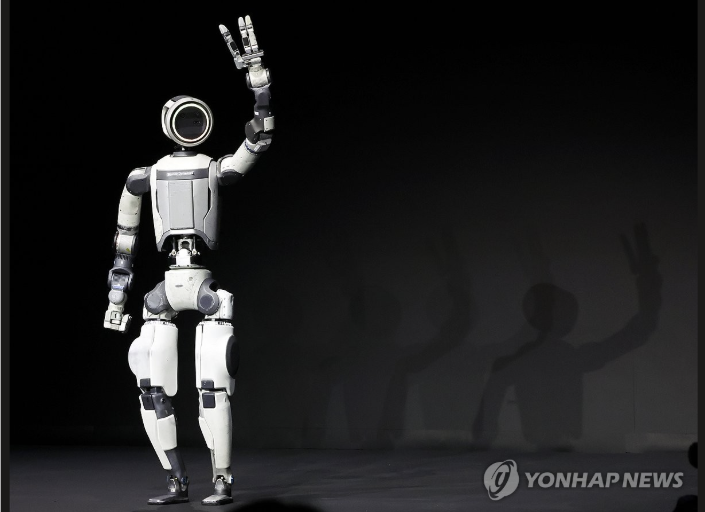

{
  "model_mode": "image2video",
  "name": "i2v_edge_noaudio",
  "enable_sound": false,
  "num_steps": 20,
  "guidance": 5.0,
  "shift": 8.0,
  "fps": 24,
  "num_frames": 121,
  "resolution": "480",
  "aspect_ratio": "16,9",
  "seed": 0
}
{
  "model_mode": "image2video",
  "name": "i2v_edge_noaudio",
  "enable_sound": false,
  "num_steps": 20,
  "guidance": 5.0,
  "shift": 8.0,
  "fps": 24,
  "num_frames": 121,
  "resolution": "480",
  "aspect_ratio": "16,9",
  "seed": 0
}


In [43]:
i2v_edge_noaudio_payload, i2v_edge_noaudio_output, i2v_edge_noaudio_model = create_payload("i2v_edge_noaudio", backend="diffusers")


### Run


In [44]:
run_diffusers_payload(i2v_edge_noaudio_payload, i2v_edge_noaudio_output, model="Cosmos3-Edge")


loading nvidia/Cosmos3-Edge...


/home/arrl/jaeyu/cosmos3/git/cosmos/.venv/lib/python3.13/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:  25%|██▌       | 1/4 [00:00<00:02,  1.44it/s]Loaded scheduler as UniPCMultistepScheduler from `scheduler` subfolder of nvidia/Cosmos3-Edge.
Instantiating AutoencoderKLWan model under default dtype torch.bfloat16.
The config attributes {'clip_output': False} were passed to AutoencoderKLWan, but are not expected and will be ignored. Please verify your config.json configuration file.
All model checkpoint weights were used when initializing AutoencoderKLWan.

All the weights of AutoencoderKLWan were initialized from the model checkpoint at /home/arrl/.cache/huggingface/hub/models--nvidia--Cosmos3-Edge/snapshots/344d602b128d1bbdacb43b08d0a3626f46343e29/vae.
If your task is similar to the task the model of the checkpoint was trained on, you can already use AutoencoderKLWan for predictions without further training.
Loaded vae as AutoencoderKLWan from `vae` subfolder of nvidia/Cosmos3-Edge.
Instantiating Cosmos3OmniTransformer model under default dtype torch.bfl

loaded pipeline in 5.4s
generating image2video i2v_edge_noaudio with Cosmos3-Edge -> /home/arrl/jaeyu/cosmos3/git/cosmos/cookbooks/cosmos3/generator/audiovisual/outputs/notebooks/diffusers/i2v_edge_noaudio/i2v_edge_noaudio.mp4


100%|██████████| 20/20 [00:56<00:00,  2.84s/it]


generated in 97.2s
wrote /home/arrl/jaeyu/cosmos3/git/cosmos/cookbooks/cosmos3/generator/audiovisual/outputs/notebooks/diffusers/i2v_edge_noaudio/i2v_edge_noaudio.mp4


PosixPath('/home/arrl/jaeyu/cosmos3/git/cosmos/cookbooks/cosmos3/generator/audiovisual/outputs/notebooks/diffusers/i2v_edge_noaudio/i2v_edge_noaudio.mp4')

### View Results


In [45]:
view_run(i2v_edge_noaudio_output)


source: /home/arrl/jaeyu/cosmos3/git/cosmos/cookbooks/cosmos3/generator/audiovisual/outputs/notebooks/diffusers/i2v_edge_noaudio/i2v_edge_noaudio.mp4 (246 KB)


## Super: Video to Video Without Audio

Super video-to-video generation using the same reference clip and conditioning frames as Nano, with audio disabled.

### Create Payload


In [46]:
# v2v_super_noaudio_payload, v2v_super_noaudio_output, v2v_super_noaudio_model = create_payload("v2v_super_noaudio", backend="diffusers")


### Run


In [47]:
# run_diffusers_payload(v2v_super_noaudio_payload, v2v_super_noaudio_output, model="Cosmos3-Super")


### View Results


In [48]:
# view_run(v2v_super_noaudio_output)


## Super: Video to Video with Audio

Super video-to-video generation on the same reference clip and conditioning frames as the Nano case, with generated audio.

### Create Payload

In [49]:
# v2vs_super_payload, v2vs_super_output, v2vs_super_model = create_payload("v2vs_super", backend="diffusers")

### Run

In [50]:
# run_diffusers_payload(v2vs_super_payload, v2vs_super_output, model="Cosmos3-Super")

### View Results

In [51]:
# view_run(v2vs_super_output)